# Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc 
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns


# Metrics
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.stats import entropy

For all the methods, we will use the same amount of data.

- We will choose cells which have at least 200 genes `sc.pp.filter_cells(adata, min_genes = 200)`

- We will choose genes which are at least in 10 cells `sc.pp.filter_genes(adata, min_cells=10)`

- As seen in the EDA,  we will choose 2000 top HVG, which represent Highly Variable Genes, as they contain actual valuable information.
This is a strict cutoff we are introducing manually, therefore we should take it into account. Maybe 2134 HVG is better, however, this seems like a reasonable value and it also represents a big dataset reduction which will improve our computational power. A support to this idea comes from this paper written by [M.D. Luecken et Al](https://www.nature.com/articles/s41592-021-01336-8) which shows that using highly variable genes actually leads to an increase in performance.

# Loading Data

In [ ]:
# processing
from data.load_data import load_wu2021, first_col, SEED, N_CELLS

def find_project_root(start=None):
    try:
        start = Path(start or __file__).resolve()   
    except NameError:
        start = Path.cwd().resolve()                
    for parent in [start] + list(start.parents):
        if (parent / "data").exists() or (parent / "README.md").exists():
            return parent
    raise FileNotFoundError("Could not find project root containing 'data/' or README.md.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
H5AD_PATH = DATA_DIR / "wu_2021_breast_cancer.h5ad"
GEO_DIR = DATA_DIR / "geo_data"

adata = load_wu2021()



In [3]:
# Same processing as before
def is_integer_counts(X, n=500):
    sub = X[:n].toarray() if hasattr(X[:n], "toarray") else np.asarray(X[:n])
    return bool(np.all(sub >= 0) and np.allclose(sub, np.round(sub)))

if not is_integer_counts(adata.X):
    if adata.raw is not None:
        adata = adata.raw.to_adata()

# Map Ensembl IDs to Gene Names if present
if "feature_name" in adata.var:
    adata.var["ensembl_id"] = adata.var_names
    adata.var_names = adata.var["feature_name"].astype(str)

adata.var_names_make_unique()

# Standardize Column Metadata
def first_col(obs, candidates):
    for c in candidates:
        if c in obs.columns:
            return c
    raise KeyError(f"None of {candidates} found in obs: {list(obs.columns)}")

COLMAP = {
    "patient":        first_col(adata.obs, ["orig.ident", "donor_id", "Patient", "patient"]),
    "subtype":        first_col(adata.obs, ["subtype", "Subtype", "clinical_subtype", "disease"]),
    "celltype":       first_col(adata.obs, ["celltype_major", "author_cell_type", "cell_type"]),
    "celltype_minor": first_col(adata.obs, ["celltype_minor", "celltype_major", "author_cell_type", "cell_type"]),
}

for std, orig in COLMAP.items():
    adata.obs[std] = adata.obs[orig].astype(str).astype("category")

# Keep subtype as a plain string inside obs to prevent categorical list aggregation errors
adata.obs["subtype"] = adata.obs["subtype"].astype(str)

# Data Filtering and Normalization

In [ ]:
N_HVG = 2000
N_LATENT = 10 # Ensures it is the same for all models
SEED = 42
MIN_GENES = 200
MIN_CELLS = 10

MODELS_DIR  = Path("models");  MODELS_DIR.mkdir(exist_ok=True)
RETRAIN = False

In [5]:
adata.layers["counts"] = adata.X.copy() # Raw counts are saved just in case

sc.pp.filter_cells(adata, min_genes=MIN_GENES)
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)


# Normalization and log-transform
sc.pp.normalize_total(adata, target_sum=1e4) # Normalizes total counts per cell to 10000
sc.pp.log1p(adata)

# Chosing HVGs
try:
    sc.pp.highly_variable_genes(
        adata, n_top_genes=N_HVG, flavor="seurat_v3",
        layer="counts", batch_key="patient", subset=True
    )
except Exception as e:
    print("Per-patient HVG selection failed, switching to global HVGs:", e)
    sc.pp.highly_variable_genes(
        adata, n_top_genes=N_HVG, flavor="seurat_v3",
        layer="counts", subset=True
    )

Per-patient HVG selection failed, switching to global HVGs: b'reciprocal condition number  7.4327e-15'


# Evaluation Metrics

In [ ]:
# Batch entropy, will be used later in the different function
def compute_batch_entropy(X, patient_labels, k=50):
    nn = NearestNeighbors(n_neighbors=k, n_jobs=-1).fit(X)
    indices = nn.kneighbors(X, return_distance=False)
    entropies = [entropy(pd.Series(patient_labels[nbrs]).value_counts(normalize=True)) for nbrs in indices]
    return np.mean(entropies)

# Baseline Model (PCA)

We will apply PCA on log-normalized data as a baseline model to compare with the remaining models.


In [6]:
adata_pca = adata.copy()
sc.pp.scale(adata_pca, max_value=10)
sc.tl.pca(adata_pca, n_comps=N_LATENT, random_state=SEED)

# Copying PCA latent embedding back to main AnnData
adata.obsm["X_pca"] = adata_pca.obsm["X_pca"].copy()

c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


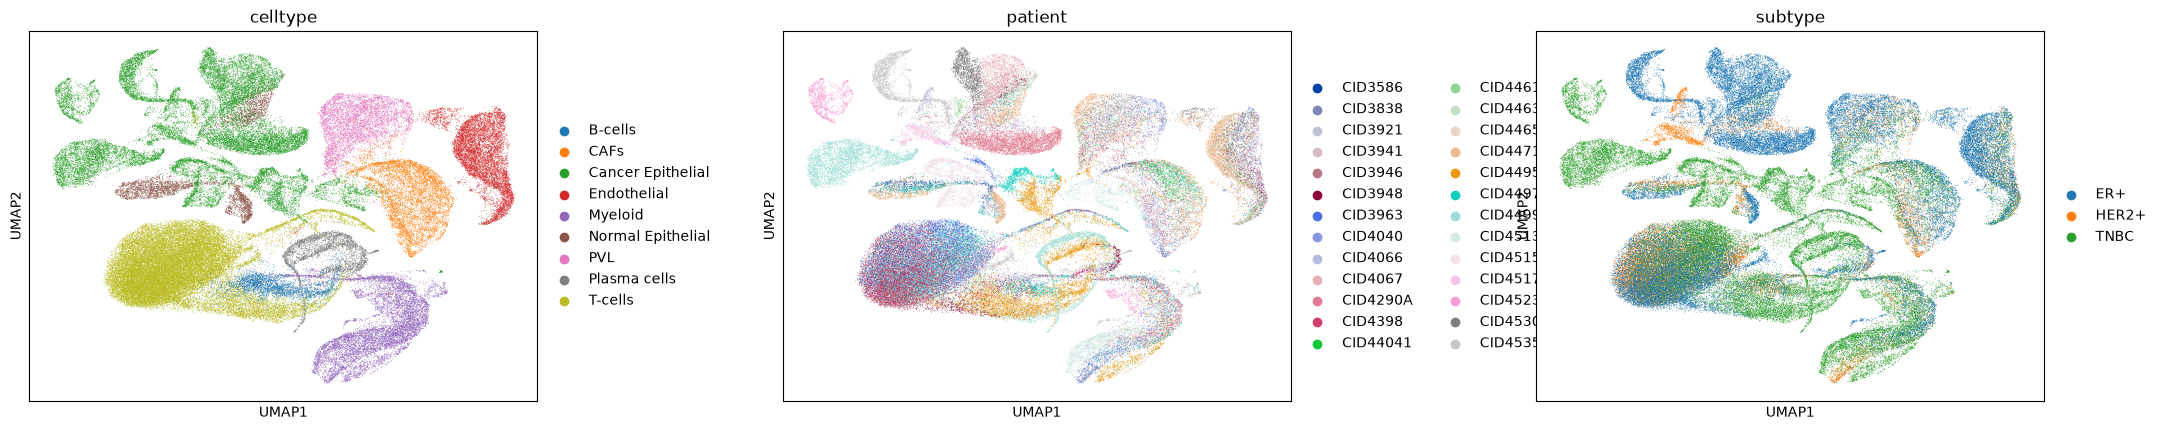

In [7]:
# KNN graph and UMAP
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_pca"] = adata.obsm["X_umap"].copy()

sc.pl.umap(adata, color=["celltype", "patient", "subtype"], wspace=0.35)

## PCA Evaluation Metrics

We will compute different evaluation metrics whihc will be used later for comparing models

*To do: explain what each of the metrics compute*

In [8]:
y_true = adata.obs["celltype"].astype(str).values
n_celltypes = adata.obs["celltype"].nunique()

# Unsupervised Biological (K-Means ARI and NMI)
kmeans = KMeans(n_clusters=n_celltypes, random_state=SEED, n_init=10)
pca_cluster_labels = kmeans.fit_predict(adata.obsm["X_pca"])

pca_ari = adjusted_rand_score(y_true, pca_cluster_labels)
pca_nmi = normalized_mutual_info_score(y_true, pca_cluster_labels)

# Silhoute score (ASW) we take a subset of our data
sub_idx = np.random.choice(adata.shape[0], size=min(10000, adata.shape[0]), replace=False)
X_pca_sub = adata.obsm["X_pca"][sub_idx]

asw_celltype = silhouette_score(X_pca_sub, adata.obs["celltype"].iloc[sub_idx])
asw_patient = silhouette_score(X_pca_sub, adata.obs["patient"].iloc[sub_idx])

pca_batch_entropy = compute_batch_entropy(adata.obsm["X_pca"], adata.obs["patient"].values, k=50)

# PCA metrics, in the future, we will save this to CSV, arrows indicate if high values is btter or not
pca_metrics = pd.DataFrame([{
    "Model": "PCA Baseline",
    "ARI (Cell Type ↑)": pca_ari,
    "NMI (Cell Type ↑)": pca_nmi,
    "ASW (Cell Type ↑)": asw_celltype,
    "ASW (Patient ↓)": asw_patient,
    "Batch Entropy (↑)": pca_batch_entropy
}]).set_index("Model")

print(pca_metrics)

              ARI (Cell Type ↑)  NMI (Cell Type ↑)  ASW (Cell Type ↑)  \
Model                                                                   
PCA Baseline           0.645611           0.711716           0.288777   

              ASW (Patient ↓)  Batch Entropy (↑)  
Model                                             
PCA Baseline        -0.192815           1.138922  


**To do: Missing conclusions, brief model explanation and analysis for PCA**

# MrVI

MrVI (Multi-Resolution Variational Inference) [P.Boyeau et al, 2025](https://www.nature.com/articles/s41592-025-02808-x) is a deep generative model designed for exploratory and comparative analysis of single-cell sequencing data from multiple samples

Takes as input two types of sample-level covariates:

- Target Covariates: (sample-level target covariates). Which refer to actual properties. It usually represents the sample ID which defined what entities will be compared. (In our case, they will be the sample ID). Given by: $s_n$

- Nuisance Covariates: Corresponds to technical factors (study of origin, sample processing site....) Given by: $b_n$



## MrVI process

![MrVI Graphical Model](images/MrVi.png)

Image taken from [scvi-tools](https://docs.scvi-tools.org/en/1.3.3/user_guide/models/mrvi.html)

The idea from MrVI is that each cell (n) is associated with two latent variables $u_n, z_n$

- **$u_n$**: Captures the variation between cell states without taking into account the sample covariates. Given by a Gaussian Mixture prior $u_n \sim MixtureOfGaussians(\mu_1, ..., \mu_k, \sum_1, ..., \sum_K, \pi_1, ..., \pi_K)$

- **$z_n$**: Captures the variation between cell states, taking into account the sample covariates but remaining unaffected by nuisance covariates. It is actually learnt from $u_n$ as well as the target covariates. $z_n|u_n \sim N(u_n, I_L)$. This allows for comparative analysis, as a useful question we could extract from this would be: "If cell n, originally in patient A (s), cambe from patient B (s'), how would the state $z_n$ look like". This is one of the main advantages of MrVI

- **$x_n$**: Models raw gene counts by decoding $z_n$ conditioned on nuisance covariates $b_n$ and cell library size $l_n$ using a Negative Binomial distribution:
  $$x_n \mid z_n, b_n \sim \text{NegativeBinomial}(\mu(z_n, b_n), r)$$

Actual $x_n$ is computed using $h_n$ which receives the latent $z_n$ and nuisance factors $b_n$ which pass through a multi-head attention layer so the output is normalized (this also uses a specific matrix and bias, more details in the paper)

## MrVI Inference

Variatonal inference is used to approximate the posterior of $u_n$ and $z_n$.

$q_\phi (u_n|x_n) = N(\mu_\phi (x_n), \sigma_\phi^2(x_n)I$

$z_n = u_n + f_\phi(u_n, s_n)$

Where the values are given by neural networks such as encoders or using multi-head attention

**Important: Model is already trained, no need to run the below function, we just need to load the existing pre-trained model**

In [9]:
from scvi.external import MRVI

# Training MrVI
# Despite there being two separate latents which encode different information, they both do it in the same dimensions
def train_mrvi(adata, name="mrvi", sample_key="patient", batch_key=None, n_latent=N_LATENT, **model_kwargs):
    a = adata.copy()

    # Registers the dataset
    MRVI.setup_anndata(
        a, 
        layer="counts", 
        sample_key=sample_key, # Target covariate
        batch_key=batch_key # Nuisance factors 
    )

    path = MODELS_DIR / name
    if path.exists() and not RETRAIN:
        model = MRVI.load(path, adata=a)
    else:
        model = MRVI(a, n_latent=n_latent, **model_kwargs)
        model.train(max_epochs=400, early_stopping=True, check_val_every_n_epoch=1) # The tutorial uses 400 epochs, just in case, we also apply early stopping
        model.save(path, overwrite=True)

    return model, a

# Training MrVI
mrvi_model, mrvi_adata = train_mrvi(adata, name="mrvi_patient", sample_key="patient")


C:\Users\19aca\AppData\Local\Temp\ipykernel_6948\1694144229.py:20: DeprecationWarning: You are using the Torch Version of MrVI, starting v1.4.3, This will become the default version of MrVI instead of the Jax backend version, which will be removed in v1.5
  model = MRVI(a, n_latent=n_latent, **model_kwargs)
c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\scvi\external\mrvi\_model.py:158: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  self.n_obs_per_sample = torch.Tensor(
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamle

Epoch 189/400:  47%|████▋     | 189/400 [1:08:56<1:16:57, 21.88s/it, v_num=1, train_loss=413]
Monitored metric elbo_validation did not improve in the last 15 records. Best score: 408.907. Signaling Trainer to stop.


The ELBO loss for this model is given by:

$$
ELBO(\theta, \phi) = E_{x,s,b} E_{q_\phi(u|x)}[\log \frac{p_\theta(x|z,b) p_\theta(z|u,s) p_\theta(u)}{q_\phi(u|x)}]
$$

This is just for understanding purposes, it is also important to note that the final ELBO loss actually includes a penalty term to ensure that there is a distance between z and u so they do not represent the same element

Visualizing the ELBO loss to see for convergence or potential overfitting.

history keys: ['kl_weight', 'validation_loss', 'elbo_validation', 'reconstruction_loss_validation', 'kl_local_validation', 'kl_global_validation', 'train_loss', 'elbo_train', 'reconstruction_loss_train', 'kl_local_train', 'kl_global_train']


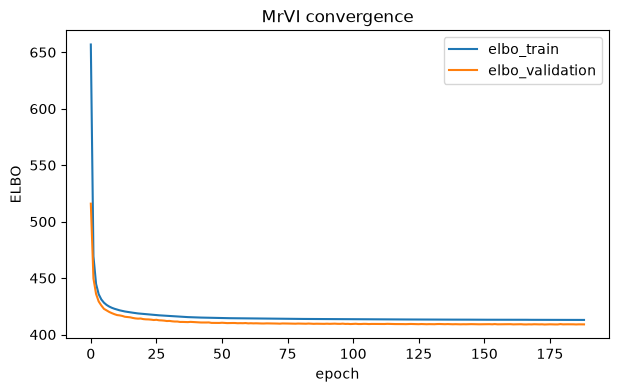

In [10]:
h = mrvi_model.history
print("history keys:", list(h.keys()))   # confirm the validation key name
fig, ax = plt.subplots(figsize=(7, 4))
for key in ("elbo_train", "elbo_validation"):
    if key in h:
        ax.plot(h[key].values.ravel(), label=key)
ax.set(xlabel="epoch", ylabel="ELBO", title="MrVI convergence")
ax.legend()
plt.show()

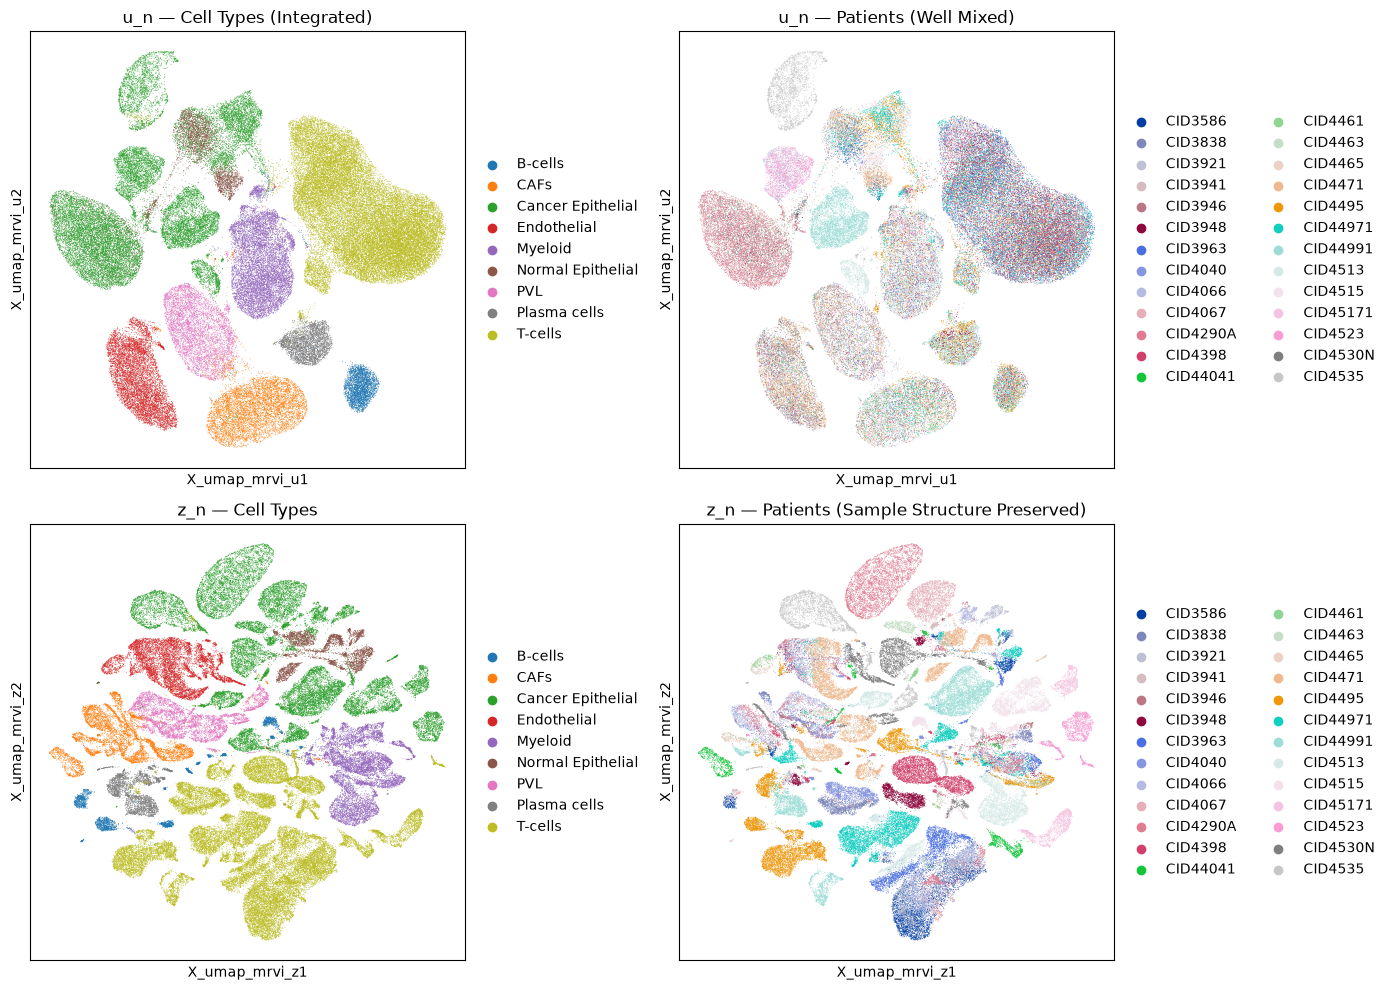

In [ ]:
adata.obsm["X_mrvi_u"] = mrvi_model.get_latent_representation(adata=mrvi_adata, give_z=False) # U latent
adata.obsm["X_mrvi_z"] = mrvi_model.get_latent_representation(adata=mrvi_adata, give_z=True) # Z latent

sc.pp.neighbors(adata, use_rep="X_mrvi_u", key_added="mrvi_u_neighbors")
sc.tl.umap(adata, neighbors_key="mrvi_u_neighbors")
adata.obsm["X_umap_mrvi_u"] = adata.obsm["X_umap"].copy()

sc.pp.neighbors(adata, use_rep="X_mrvi_z", key_added="mrvi_z_neighbors")
sc.tl.umap(adata, neighbors_key="mrvi_z_neighbors")
adata.obsm["X_umap_mrvi_z"] = adata.obsm["X_umap"].copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sc.pl.embedding(
    adata, 
    basis="X_umap_mrvi_u", 
    color="celltype", 
    ax=axes[0, 0], 
    show=False, 
    title="u_n — Cell Types (Integrated)"
)
sc.pl.embedding(
    adata, 
    basis="X_umap_mrvi_u", 
    color="patient", 
    ax=axes[0, 1], 
    show=False, 
    title="u_n — Patients (Well Mixed)"
)

sc.pl.embedding(
    adata, 
    basis="X_umap_mrvi_z", 
    color="celltype", 
    ax=axes[1, 0], 
    show=False, 
    title="z_n — Cell Types"
)
sc.pl.embedding(
    adata, 
    basis="X_umap_mrvi_z", 
    color="patient", 
    ax=axes[1, 1], 
    show=False, 
    title="z_n — Patients (Sample Structure Preserved)"
)

plt.tight_layout()
plt.show()

We can see 4 separate graphs

First row displays the latent from u.

- Left Displays cell populations grouped into distinct clusters

- Right: Pattient labels

The main idea we can extract from here is that the latent space for $u_n$ clearly isolated cell identity without taking into account donor-specific covariates

Bottom row displays the latent from z.

- Left: Split by cell type, however, we can see that the main cells are split, dont show clear clusters as in the above one.

- Right: Align directly with patient IDs. Shows the effect of introducing target sample covariates $s_n$ in this case, patient ID which captures donor-to-donor variation

Cancer epithelial cells group together clearly for the latent space $u_n$. In $z_n$ cancer epithelial cells split into specific patients, showing variation across patients.

## MrVI Evaluation Metrics

As we have different latent spaces which encode different information and have different goals, we will provide the emtrics for both of their latent spaces.

In [12]:
y_true = adata.obs["celltype"].astype(str).values
n_celltypes = adata.obs["celltype"].nunique()

# 10000 cell subsample for Silhouette Score
np.random.seed(SEED)
sub_idx = np.random.choice(adata.shape[0], size=min(10000, adata.shape[0]), replace=False)

mrvi_results = []
for name, rep_key in [("MrVI (u_n)", "X_mrvi_u"), ("MrVI (z_n)", "X_mrvi_z")]:
    emb = adata.obsm[rep_key]

    kmeans = KMeans(n_clusters=n_celltypes, random_state=SEED, n_init=10)
    cluster_labels = kmeans.fit_predict(emb)
    
    ari = adjusted_rand_score(y_true, cluster_labels)
    nmi = normalized_mutual_info_score(y_true, cluster_labels)

    emb_sub = emb[sub_idx]
    asw_celltype = silhouette_score(emb_sub, adata.obs["celltype"].iloc[sub_idx])
    asw_patient = silhouette_score(emb_sub, adata.obs["patient"].iloc[sub_idx])

    batch_ent = compute_batch_entropy(emb, adata.obs["patient"].values, k=50)
    
    mrvi_results.append({
        "Model": name,
        "ARI (Cell Type ↑)": ari,
        "NMI (Cell Type ↑)": nmi,
        "ASW (Cell Type ↑)": asw_celltype,
        "ASW (Patient ↓)": asw_patient,
        "Batch Entropy (↑)": batch_ent
    })

mrvi_metrics = pd.DataFrame(mrvi_results).set_index("Model")
print(mrvi_metrics)

            ARI (Cell Type ↑)  NMI (Cell Type ↑)  ASW (Cell Type ↑)  \
Model                                                                 
MrVI (u_n)           0.817147           0.822719           0.395329   
MrVI (z_n)           0.774900           0.775063           0.303239   

            ASW (Patient ↓)  Batch Entropy (↑)  
Model                                           
MrVI (u_n)        -0.188148           1.774382  
MrVI (z_n)        -0.048180           0.285536  


**TODO: METRICS ANALYSIS**